# 01 · Dataset sintético de documentos de transporte

**Cenário (fictício):** a *TransLog Brasil* recebe milhares de CT-e/DACTE por mês em três formatos: PDF estruturado, e-mails de operação em texto livre e digitalizações com OCR ruidoso. Este notebook explora o dataset **sintético** (gerado por `src/promptlab/dataset.py`, determinístico por seed) usado em todos os experimentos.

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


In [2]:
from promptlab.dataset import generate
from promptlab.schema import FIELDS
docs = generate(150, seed=42)
df = pd.DataFrame([{**d.truth, 'style': d.style, 'doc_id': d.doc_id} for d in docs])
df.groupby('style').size().rename('documentos').to_frame()

,documentos
style,
email,52
estruturado,49
ocr,49


## Um exemplo de cada estilo
A dificuldade cresce de `estruturado` → `ocr` → `email` (texto livre, datas por extenso, toneladas, placa ausente).

In [3]:
for style in ['estruturado', 'ocr', 'email']:
    d = next(x for x in docs if x.style == style)
    print(f'===== {style.upper()} =====\n{d.text}\n')

===== ESTRUTURADO =====
DACTE - DOCUMENTO AUXILIAR DO CONHECIMENTO DE TRANSPORTE ELETRÔNICO
Numero do documento: 277747
Data de emissao: 08/03/2026
Remetente: Kappa Eletrodomésticos ME
CNPJ remetente: 88.496.965/0001-68
Destinatario: Mantiqueira Cosméticos S.A.
CNPJ destinatario: 32.871.012/0001-88
Origem: Recife/PE
Destino: Goiânia/GO
Peso bruto: 11.323,8 kg
Volumes: 406
Valor da mercadoria: R$ 259.062,14
Valor do frete: R$ 8.422,37
Placa do veiculo: RTJ8A87
Documento sem valor fiscal. Consulte a chave de acesso no portal.

===== OCR =====
DACTE  -  CONHECIMENTO  DE  TRANSPORTE
N DOC.:  605398   EMISSAO:  23/04/2026
REMET.:  MANTIQUEIRA INDÚSTRIA TÊXTIL EIRELI
CNPJ REM.:  10.341.316/0001-09
DEST.:  UMBU EQUIPAMENTOS MÉDICOS EIRELI
CNPJ DEST.:  47.525.534/0O01-03
ORIG: SALVADOR/BA      DEST: CAMPINAS/SP
PESO BR.:  12.656,6 KG    VOL.:  350
VL. MERC.:  246.781,39
VL. FRETE:  8.598,19
PLACA:  FRN-4422

===== EMAIL =====
Olá, time!

Confirmo o embarque do documento 619177 (emissão: 2 de j

## Distribuição dos campos numéricos e campos ausentes
~30% dos documentos **não informam a placa**: o gabarito é `null` e um modelo que inventa uma placa é contabilizado como *alucinação*.

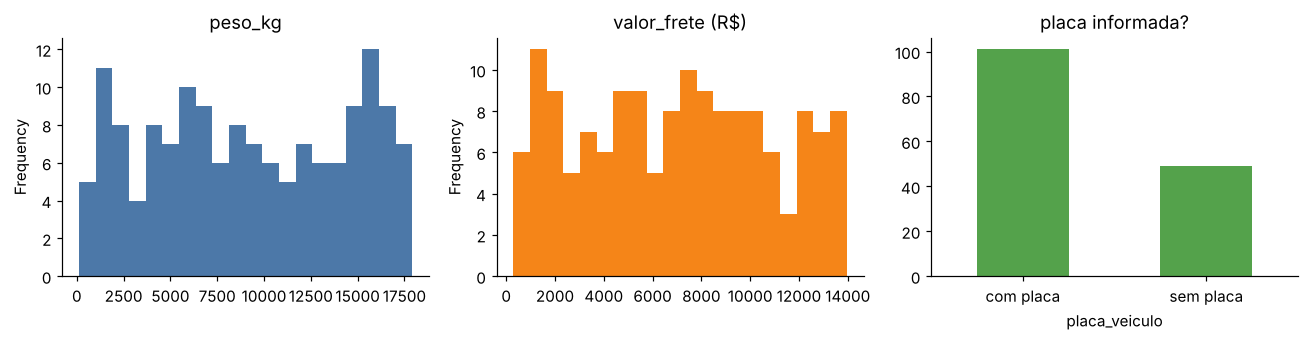

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
df['peso_kg'].plot.hist(bins=20, ax=axes[0], color='#4C78A8'); axes[0].set_title('peso_kg')
df['valor_frete'].plot.hist(bins=20, ax=axes[1], color='#F58518'); axes[1].set_title('valor_frete (R$)')
df['placa_veiculo'].isna().map({True: 'sem placa', False: 'com placa'}).value_counts().plot.bar(ax=axes[2], color='#54A24B', rot=0)
axes[2].set_title('placa informada?')
plt.tight_layout(); plt.show()

## Por que um baseline regex?
Antes de gastar tokens, medimos o *piso*: regex por rótulo. Se o regex já resolvesse tudo, LLM seria desperdício.

In [5]:
from promptlab.baseline import extract
from promptlab.evaluate import score_document
rows = []
for d in docs:
    s = score_document(d.truth, extract(d.text))
    rows.append({'style': d.style, 'acc': sum(v == 'correct' for v in s.values()) / len(s)})
pd.DataFrame(rows).groupby('style')['acc'].mean().round(3).to_frame('acurácia por campo (regex)')

,acurácia por campo (regex)
style,
email,0.018
estruturado,1.000
ocr,0.030
